In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

# -------------------------
# 1. CONNECTIONS DATASET
# -------------------------

n_connections = 100

connections = pd.DataFrame({
    'connection': [f'C{i:03d}' for i in range(1, n_connections + 1)],
    'type': np.random.choice(
        ['Residential', 'Commercial'],
        n_connections,
        p=[0.75, 0.25]
    ),
    'locality': np.random.choice(
        ['North Zone', 'South Zone', 'East Zone', 'West Zone'],
        n_connections
    ),
    'household_size_band': np.random.choice(
        ['1-2', '3-4', '5+'],
        n_connections
    )
})

# Add inconsistent connection types intentionally
connections.loc[5, 'type'] = 'residential'
connections.loc[15, 'type'] = 'COMMERCIAL'


# -------------------------
# 2. WEATHER DATASET
# -------------------------

dates = pd.date_range(
    start='2026-01-01',
    end='2026-06-30',
    freq='D'
)

weather = pd.DataFrame({
    'date': dates
})

weather['temperature'] = np.random.normal(
    30,
    4,
    len(weather)
).round(1)

weather['rain'] = np.random.choice(
    [0, 0, 0, 2, 5, 10, 20],
    len(weather)
)


# -------------------------
# 3. METER DATASET
# -------------------------

records = []

for connection in connections['connection']:

    connection_type = connections.loc[
        connections['connection'] == connection,
        'type'
    ].iloc[0].lower()

    if 'commercial' in connection_type:
        base_usage = 500
    else:
        base_usage = 200

    for date in dates:

        temperature = weather.loc[
            weather['date'] == date,
            'temperature'
        ].iloc[0]

        rain = weather.loc[
            weather['date'] == date,
            'rain'
        ].iloc[0]

        usage = (
            base_usage
            + (temperature - 25) * 5
            - rain * 2
            + np.random.normal(0, 25)
        )

        records.append([
            date,
            connection,
            round(max(usage, 0), 2)
        ])

meter = pd.DataFrame(
    records,
    columns=['date', 'connection', 'usage']
)


# Add sudden spikes
spike_indices = np.random.choice(
    meter.index,
    40,
    replace=False
)

meter.loc[spike_indices, 'usage'] *= 3


# Add negative values intentionally
negative_indices = np.random.choice(
    meter.index,
    10,
    replace=False
)

meter.loc[negative_indices, 'usage'] = -50


# Add missing values
missing_indices = np.random.choice(
    meter.index,
    20,
    replace=False
)

meter.loc[missing_indices, 'usage'] = np.nan


# Add duplicate records
meter = pd.concat(
    [meter, meter.iloc[:10]],
    ignore_index=True
)


# -------------------------
# 4. BILLING DATASET
# -------------------------

billing = meter.copy()

billing['billing_cycle'] = (
    billing['date'].dt.to_period('M').astype(str)
)

billing['charge'] = (
    billing['usage'].fillna(0) * 0.05
).round(2)

billing = billing[
    ['connection', 'billing_cycle', 'charge']
]


# -------------------------
# 5. MAINTENANCE DATASET
# -------------------------

maintenance_connections = np.random.choice(
    connections['connection'],
    25,
    replace=False
)

maintenance = pd.DataFrame({
    'connection': maintenance_connections,

    'leak_report': np.random.choice(
        ['Minor Leak', 'Major Leak'],
        25
    ),

    'repair_date': np.random.choice(
        dates[30:-30],
        25
    )
})

# Add unmatched maintenance record
maintenance.loc[len(maintenance)] = [
    'C999',
    'Minor Leak',
    pd.Timestamp('2026-04-10')
]


# -------------------------
# SAVE ALL DATASETS
# -------------------------

meter.to_csv('meter.csv', index=False)
connections.to_csv('connections.csv', index=False)
billing.to_csv('billing.csv', index=False)
weather.to_csv('weather.csv', index=False)
maintenance.to_csv('maintenance.csv', index=False)

print("All 5 datasets created successfully!")

All 5 datasets created successfully!


In [3]:
meter = pd.read_csv('meter.csv')
connections = pd.read_csv('connections.csv')
billing = pd.read_csv('billing.csv')
weather = pd.read_csv('weather.csv')
maintenance = pd.read_csv('maintenance.csv')

In [4]:
print("METER DATA")
display(meter.head())

print("CONNECTION DATA")
display(connections.head())

print("BILLING DATA")
display(billing.head())

print("WEATHER DATA")
display(weather.head())

print("MAINTENANCE DATA")
display(maintenance.head())

METER DATA


,date,connection,usage
0,2026-01-01,C001,163.52
1,2026-01-02,C001,226.76
2,2026-01-03,C001,219.94
3,2026-01-04,C001,270.06
4,2026-01-05,C001,232.85


CONNECTION DATA


,connection,type,locality,household_size_band
0,C001,Residential,East Zone,1-2
1,C002,Commercial,West Zone,1-2
2,C003,Residential,East Zone,5+
3,C004,Residential,North Zone,3-4
4,C005,Residential,West Zone,3-4


BILLING DATA


,connection,billing_cycle,charge
0,C001,2026-01,8.18
1,C001,2026-01,11.34
2,C001,2026-01,11.00
3,C001,2026-01,13.50
4,C001,2026-01,11.64


WEATHER DATA


,date,temperature,rain
0,2026-01-01,30.0,0
1,2026-01-02,31.7,0
2,2026-01-03,29.4,10
3,2026-01-04,33.5,5
4,2026-01-05,35.2,10


MAINTENANCE DATA


,connection,leak_report,repair_date
0,C066,Major Leak,2026-02-04
1,C071,Major Leak,2026-02-08
2,C080,Minor Leak,2026-03-31
3,C084,Major Leak,2026-02-19
4,C069,Minor Leak,2026-04-26


In [5]:
print("Meter:", meter.shape)
print("Connections:", connections.shape)
print("Billing:", billing.shape)
print("Weather:", weather.shape)
print("Maintenance:", maintenance.shape)

Meter: (18110, 3)
Connections: (100, 4)
Billing: (18110, 3)
Weather: (181, 3)
Maintenance: (26, 3)


In [6]:
meter.info()
connections.info()
billing.info()
weather.info()
maintenance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        18110 non-null  object 
 1   connection  18110 non-null  object 
 2   usage       18090 non-null  float64
dtypes: float64(1), object(2)
memory usage: 424.6+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   connection           100 non-null    object
 1   type                 100 non-null    object
 2   locality             100 non-null    object
 3   household_size_band  100 non-null    object
dtypes: object(4)
memory usage: 3.3+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  


In [7]:
print(meter.isnull().sum())
print(connections.isnull().sum())
print(billing.isnull().sum())
print(weather.isnull().sum())
print(maintenance.isnull().sum())

date           0
connection     0
usage         20
dtype: int64
connection             0
type                   0
locality               0
household_size_band    0
dtype: int64
connection       0
billing_cycle    0
charge           0
dtype: int64
date           0
temperature    0
rain           0
dtype: int64
connection     0
leak_report    0
repair_date    0
dtype: int64


In [8]:
print((meter.isnull().sum() / len(meter)) * 100)

date          0.000000
connection    0.000000
usage         0.110436
dtype: float64


In [9]:
print("Meter duplicates:", meter.duplicated().sum())
print("Connection duplicates:", connections.duplicated().sum())
print("Billing duplicates:", billing.duplicated().sum())
print("Weather duplicates:", weather.duplicated().sum())
print("Maintenance duplicates:", maintenance.duplicated().sum())

Meter duplicates: 10
Connection duplicates: 0
Billing duplicates: 418
Weather duplicates: 0
Maintenance duplicates: 0


In [10]:
meter = meter.drop_duplicates()
connections = connections.drop_duplicates()
billing = billing.drop_duplicates()
weather = weather.drop_duplicates()
maintenance = maintenance.drop_duplicates()

In [11]:
meter['date'] = pd.to_datetime(meter['date'], errors='coerce')
weather['date'] = pd.to_datetime(weather['date'], errors='coerce')

In [12]:
maintenance['repair_date'] = pd.to_datetime(
    maintenance['repair_date'],
    errors='coerce'
)

In [13]:
negative_usage = meter[meter['usage'] < 0]

print("Negative usage records:")
display(negative_usage)

Negative usage records:


,date,connection,usage
3186,2026-04-20,C018,-50.0
3977,2026-06-26,C022,-50.0
4058,2026-03-18,C023,-50.0
6719,2026-01-23,C038,-50.0
7698,2026-04-07,C043,-50.0
7748,2026-05-27,C043,-50.0
7863,2026-03-22,C044,-50.0
9514,2026-04-13,C053,-50.0
14574,2026-04-05,C081,-50.0
17665,2026-04-19,C098,-50.0


In [14]:
meter.loc[meter['usage'] < 0, 'usage'] = np.nan

In [15]:
meter['usage'] = meter['usage'].fillna(meter['usage'].median())

In [16]:
print(connections['type'].value_counts())

type
Residential    74
Commercial     24
residential     1
COMMERCIAL      1
Name: count, dtype: int64


In [17]:
connections['type'] = connections['type'].str.strip().str.lower()

In [18]:
df = pd.merge(
    meter,
    connections,
    on='connection',
    how='left'
)

In [19]:
df = pd.merge(
    df,
    weather,
    on='date',
    how='left'
)

In [20]:
display(df.head())
print(df.shape)

,date,connection,usage,type,locality,household_size_band,temperature,rain
0,2026-01-01,C001,163.52,residential,East Zone,1-2,30.0,0
1,2026-01-02,C001,226.76,residential,East Zone,1-2,31.7,0
2,2026-01-03,C001,219.94,residential,East Zone,1-2,29.4,10
3,2026-01-04,C001,270.06,residential,East Zone,1-2,33.5,5
4,2026-01-05,C001,232.85,residential,East Zone,1-2,35.2,10


(18100, 8)


In [21]:
df.describe()

,date,usage,temperature,rain
count,18100,18100.000000,18100.000000,18100.000000
mean,2026-03-31 23:59:59.999999744,290.442374,29.883978,5.066298
min,2026-01-01 00:00:00,71.300000,16.500000,0.000000
25%,2026-02-15 00:00:00,199.177500,26.800000,0.000000
50%,2026-04-01 00:00:00,230.860000,30.000000,2.000000
75%,2026-05-16 00:00:00,416.022500,33.100000,10.000000
max,2026-06-30 00:00:00,1670.400000,42.700000,20.000000
std,NaN,137.621075,4.393200,6.549275


In [22]:
print("Average Usage:", df['usage'].mean())
print("Median Usage:", df['usage'].median())
print("Maximum Usage:", df['usage'].max())
print("Minimum Usage:", df['usage'].min())
print("Standard Deviation:", df['usage'].std())

Average Usage: 290.44237403314924
Median Usage: 230.86
Maximum Usage: 1670.4
Minimum Usage: 71.3
Standard Deviation: 137.6210754263592


In [23]:
locality_usage = (
    df.groupby('locality')['usage']
      .sum()
      .sort_values(ascending=False)
)

print(locality_usage)

locality
North Zone    1579754.20
West Zone     1542582.48
South Zone    1075140.04
East Zone     1059530.25
Name: usage, dtype: float64


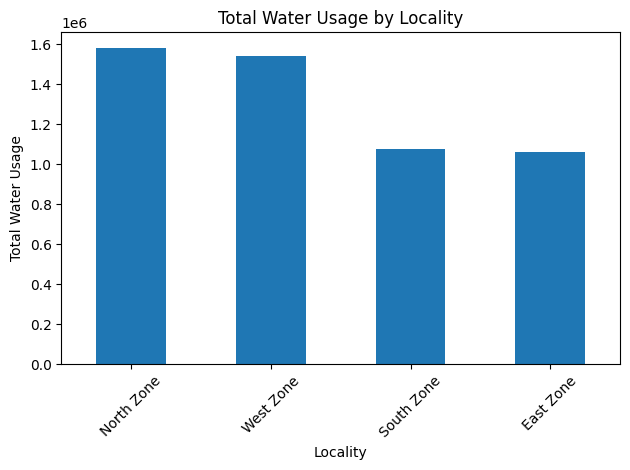

In [24]:
locality_usage.plot(kind='bar')

plt.title('Total Water Usage by Locality')
plt.xlabel('Locality')
plt.ylabel('Total Water Usage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
print(df[['usage', 'temperature', 'rain']].corr())

                usage  temperature      rain
usage        1.000000     0.170401 -0.111873
temperature  0.170401     1.000000 -0.109690
rain        -0.111873    -0.109690  1.000000


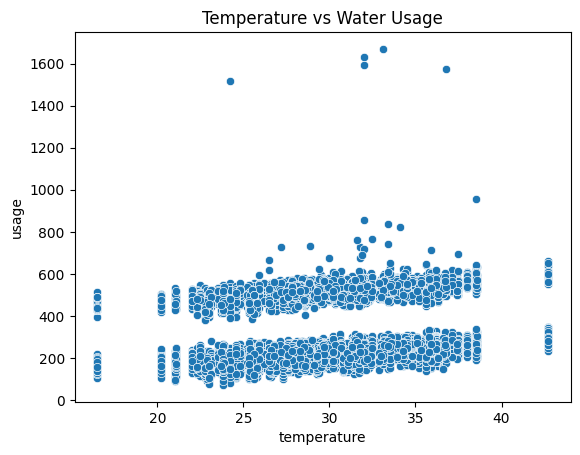

In [26]:
sns.scatterplot(data=df, x='temperature', y='usage')

plt.title('Temperature vs Water Usage')
plt.show()

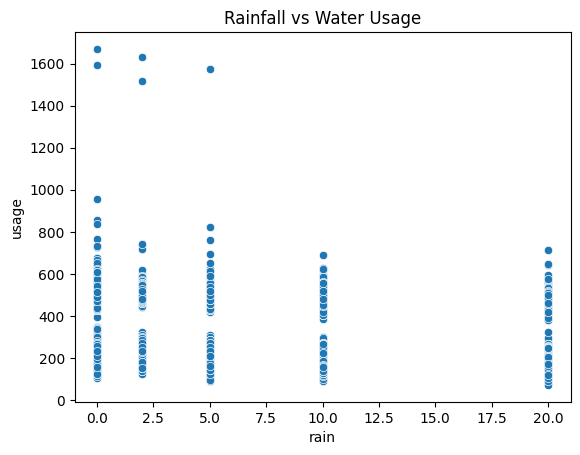

In [27]:
sns.scatterplot(data=df, x='rain', y='usage')

plt.title('Rainfall vs Water Usage')
plt.show()

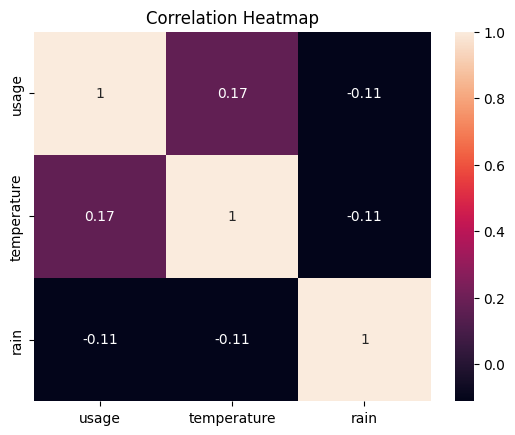

In [28]:
sns.heatmap(
    df[['usage', 'temperature', 'rain']].corr(),
    annot=True
)

plt.title('Correlation Heatmap')
plt.show()

In [29]:
df = df.sort_values(['connection', 'date'])

In [30]:
df['previous_usage'] = (
    df.groupby('connection')['usage'].shift(1)
)

In [31]:
df['usage_change'] = df['usage'] - df['previous_usage']

In [32]:
df['usage_pct_change'] = (
    df.groupby('connection')['usage'].pct_change() * 100
)

In [33]:
df['rolling_mean'] = (
    df.groupby('connection')['usage']
      .transform(lambda x: x.rolling(7, min_periods=1).mean())
)

df['rolling_std'] = (
    df.groupby('connection')['usage']
      .transform(lambda x: x.rolling(7, min_periods=2).std())
)

df['spike_flag'] = (
    df['usage'] >
    df['rolling_mean'] + 2 * df['rolling_std']
)

In [34]:
spikes = df[df['spike_flag'] == True]

display(
    spikes[
        ['date', 'connection', 'usage',
         'rolling_mean', 'usage_change']
    ]
)

,date,connection,usage,rolling_mean,usage_change
43,2026-02-13,C001,306.12,207.617143,87.95
300,2026-04-30,C002,1573.62,666.445714,1016.22
405,2026-02-13,C003,303.76,207.268571,113.90
520,2026-06-08,C003,728.40,270.731429,532.93
1059,2026-06-04,C006,626.10,267.781429,387.04
...,...,...,...,...,...
16827,2026-06-25,C093,1670.40,668.581429,1128.96
17229,2026-02-04,C096,418.74,247.587143,184.39
17633,2026-03-18,C098,732.36,290.475714,491.69
17894,2026-06-06,C099,240.95,208.694286,43.16


In [35]:
spike_connections = (
    spikes.groupby('connection')
          .size()
          .sort_values(ascending=False)
)

print(spike_connections.head(10))

connection
C019    5
C088    3
C043    3
C041    3
C062    3
C083    3
C067    2
C042    2
C003    2
C046    2
dtype: int64


In [36]:
type_usage = df.groupby('type')['usage'].agg(
    ['mean', 'median', 'sum', 'max']
)

print(type_usage)

                   mean  median         sum      max
type                                                
commercial   515.281675  515.10  2331649.58  1670.40
residential  215.495940  215.02  2925357.39   955.65


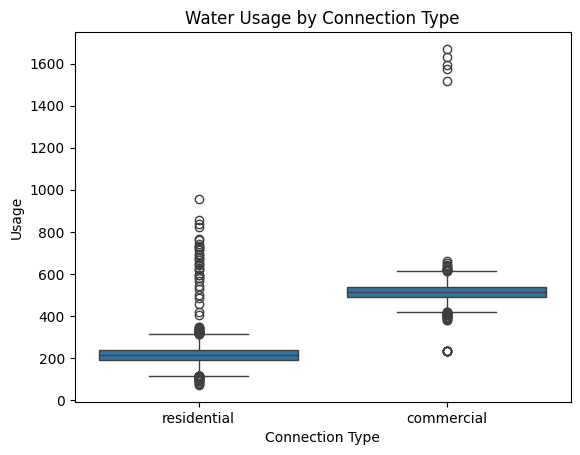

In [37]:
sns.boxplot(data=df, x='type', y='usage')

plt.title('Water Usage by Connection Type')
plt.xlabel('Connection Type')
plt.ylabel('Usage')
plt.show()

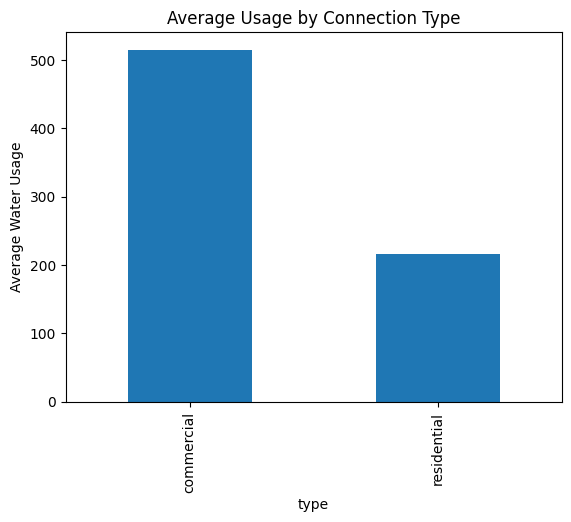

In [38]:
avg_type = df.groupby('type')['usage'].mean()

avg_type.plot(kind='bar')

plt.title('Average Usage by Connection Type')
plt.ylabel('Average Water Usage')
plt.show()

In [39]:
repair_df = pd.merge(
    df,
    maintenance[['connection', 'repair_date']],
    on='connection',
    how='inner'
)

In [40]:
repair_df['period'] = np.where(
    repair_df['date'] < repair_df['repair_date'],
    'Before Repair',
    'After Repair'
)

In [41]:
repair_df['days_from_repair'] = (
    repair_df['date'] - repair_df['repair_date']
).dt.days

repair_window = repair_df[
    repair_df['days_from_repair'].between(-30, 30)
].copy()

repair_window['period'] = np.where(
    repair_window['days_from_repair'] < 0,
    'Before Repair',
    'After Repair'
)

In [42]:
repair_comparison = (
    repair_window.groupby('period')['usage'].mean()
)

print(repair_comparison)

period
After Repair     301.617148
Before Repair    300.071480
Name: usage, dtype: float64


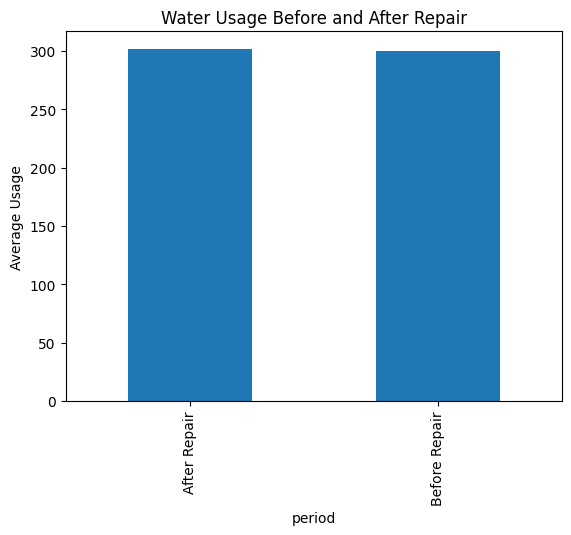

In [43]:
repair_comparison.plot(kind='bar')

plt.title('Water Usage Before and After Repair')
plt.ylabel('Average Usage')
plt.show()

In [44]:
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()
df['day_of_week'] = df['date'].dt.day_name()
df['year'] = df['date'].dt.year

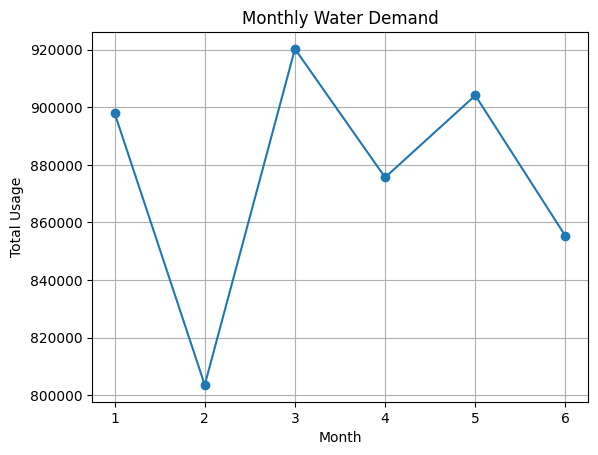

In [45]:
monthly_usage = df.groupby('month')['usage'].sum()

monthly_usage.plot(kind='line', marker='o')

plt.title('Monthly Water Demand')
plt.xlabel('Month')
plt.ylabel('Total Usage')
plt.grid(True)
plt.show()

In [46]:
print("Peak month number:", monthly_usage.idxmax())
print("Peak usage:", monthly_usage.max())

Peak month number: 3
Peak usage: 920300.0


In [47]:
daily_pattern = df.groupby('day_of_week')['usage'].mean()

print(daily_pattern)

day_of_week
Friday       284.568692
Monday       294.584231
Saturday     288.024527
Sunday       295.632092
Thursday     292.277935
Tuesday      290.005019
Wednesday    287.906592
Name: usage, dtype: float64


In [48]:
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [49]:
df['previous_usage'] = df.groupby('connection')['usage'].shift(1)

df['usage_change'] = (
    df['usage'] - df['previous_usage']
)

In [50]:
df['rolling_7day_usage'] = (
    df.groupby('connection')['usage']
      .transform(lambda x: x.rolling(7, min_periods=1).mean())
)

In [51]:
df['spike_flag'] = (
    df['usage'] >
    df['rolling_mean'] + 2 * df['rolling_std']
).astype(int)

In [52]:
encoded_df = pd.get_dummies(
    df,
    columns=['type', 'locality'],
    drop_first=True
)

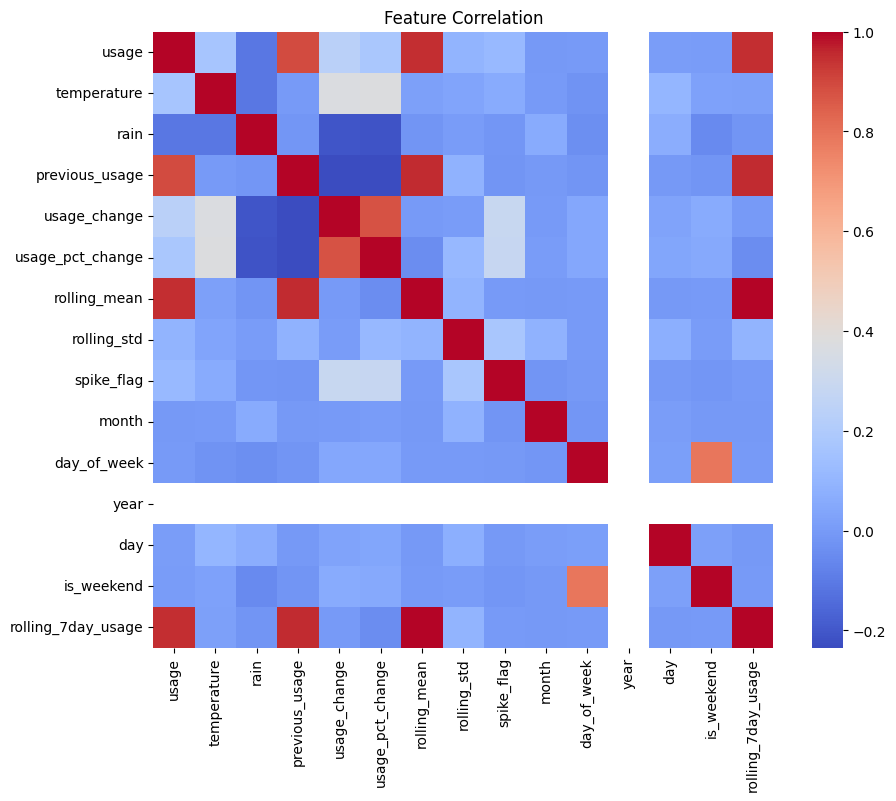

In [53]:
numeric_df = encoded_df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, cmap='coolwarm')
plt.title('Feature Correlation')
plt.show()

In [54]:
df.to_csv(
    'cleaned_water_usage.csv',
    index=False
)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [55]:
import pandas as pd

df = pd.read_csv('cleaned_water_usage.csv')
maintenance = pd.read_csv('maintenance.csv')

df['date'] = pd.to_datetime(df['date'])
maintenance['repair_date'] = pd.to_datetime(maintenance['repair_date'])

print("Files loaded successfully")

Files loaded successfully


In [56]:
repair_df = pd.merge(
    df,
    maintenance[['connection', 'repair_date']],
    on='connection',
    how='inner'
)

print(repair_df[['connection', 'date', 'usage', 'repair_date']].head())

  connection       date   usage repair_date
0       C001 2026-01-01  163.52  2026-05-15
1       C001 2026-01-02  226.76  2026-05-15
2       C001 2026-01-03  219.94  2026-05-15
3       C001 2026-01-04  270.06  2026-05-15
4       C001 2026-01-05  232.85  2026-05-15


In [57]:
repair_df['period'] = 'After Repair'

repair_df.loc[
    repair_df['date'] < repair_df['repair_date'],
    'period'
] = 'Before Repair'

print(repair_df[['date', 'connection', 'usage', 'repair_date', 'period']].head(10))

        date connection   usage repair_date         period
0 2026-01-01       C001  163.52  2026-05-15  Before Repair
1 2026-01-02       C001  226.76  2026-05-15  Before Repair
2 2026-01-03       C001  219.94  2026-05-15  Before Repair
3 2026-01-04       C001  270.06  2026-05-15  Before Repair
4 2026-01-05       C001  232.85  2026-05-15  Before Repair
5 2026-01-06       C001  238.72  2026-05-15  Before Repair
6 2026-01-07       C001  203.50  2026-05-15  Before Repair
7 2026-01-08       C001  180.42  2026-05-15  Before Repair
8 2026-01-09       C001  213.61  2026-05-15  Before Repair
9 2026-01-10       C001  193.10  2026-05-15  Before Repair


In [58]:
print(repair_df['period'].value_counts())

period
After Repair     2337
Before Repair    2188
Name: count, dtype: int64


In [59]:
print(
    repair_df.groupby('period')['usage'].mean()
)

period
After Repair     311.827595
Before Repair    285.197815
Name: usage, dtype: float64


In [60]:
repair_df.to_csv(
    'repair_analysis.csv',
    index=False
)

print("repair_analysis.csv created successfully!")

repair_analysis.csv created successfully!
